# Project Name:
# DeepFER: Facial Emotion Recognition Using Deep Learning — A Comparative Study of CNN and Transfer Learning Approaches

# Summary: 
DeepFER implements and compares two deep learning approaches for facial emotion recognition on the FER2013 dataset (35,887 grayscale 48×48 images across 7 emotion classes). A custom CNN architecture with batch normalization, dropout regularization, and global average pooling was trained from scratch, achieving 64.78% test accuracy (macro-F1: 0.603). A transfer learning approach using a pretrained ResNet34 backbone, fine-tuned in two phases (frozen backbone → unfrozen layer3/layer4), achieved 68.78% test accuracy (macro-F1: 0.668) — a ~4-point improvement, demonstrating the value of pretrained visual features even when adapting from natural images (ImageNet) to a domain-specific task (facial expressions). Both models were trained with class-weighted loss to address FER2013's inherent class imbalance (disgust: 436 images vs. happy: 7,215 images), label smoothing, and evaluated using test-time augmentation. Both models perform strongly on visually distinctive expressions (happy, surprise) but struggle more with fear, which is frequently confused with sad and surprise due to overlapping facial action units.

# Problem Statement:
Facial emotion recognition is inherently challenging due to subtle inter-class similarities (e.g., fear vs. surprise), significant class imbalance in real-world datasets, and variability in lighting, pose, and expression intensity across individuals. Traditional rule-based and handcrafted-feature methods fail to generalize across diverse populations and conditions. This project addresses the problem of automatically classifying human facial expressions into seven emotion categories — angry, disgust, fear, happy, neutral, sad, and surprise — using deep learning, and evaluates whether transfer learning from large-scale pretrained networks offers a meaningful advantage over a custom CNN trained from scratch on a comparatively small and imbalanced dataset (FER2013).

In [1]:
# SECTION 1: SETUP & IMPORTS

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    # Speeds up training on fixed-size inputs (T4 benefits from this)
    torch.backends.cudnn.benchmark = True

Using device: cuda
GPU: Tesla T4


In [2]:
# SECTION 2: CONFIGURATION

class Config:
    # ---- Paths ----
    TRAIN_DIR = "/kaggle/input/datasets/ankit20554/dataset4/archive-3/train"
    TEST_DIR  = "/kaggle/input/datasets/ankit20554/dataset4/archive-3/test"

    # ---- Data ----
    IMG_SIZE_CNN    = 48
    IMG_SIZE_RESNET = 224
    NUM_CLASSES     = 7
    CLASS_NAMES     = ["angry", "disgust", "fear", "happy",
                       "neutral", "sad", "surprise"]

    # ---- Training (shared) ----
    BATCH_SIZE   = 64
    NUM_WORKERS  = 2
    VAL_SPLIT    = 0.1
    LABEL_SMOOTHING = 0.1   # softens hard labels -> reduces overfitting to noisy FER2013 labels

    # ---- Custom CNN ----
    CNN_EPOCHS = 60          # increased from 40 -> more room to converge
    CNN_LR     = 1e-3

    # ---- Transfer Learning (ResNet34) ----
    RESNET_FROZEN_EPOCHS   = 8
    RESNET_FINETUNE_EPOCHS = 25   # increased from 15 -> deeper fine-tune
    RESNET_HEAD_LR         = 1e-4
    RESNET_FINETUNE_LR     = 3e-5

    # ---- Test-Time Augmentation ----
    TTA_ROUNDS = 5   # number of augmented passes averaged at test time

    # ---- Misc ----
    CHECKPOINT_DIR = "/kaggle/working/checkpoints"

cfg = Config()
os.makedirs(cfg.CHECKPOINT_DIR, exist_ok=True)

print("Configuration loaded.")
print(f"Classes: {cfg.CLASS_NAMES}")

Configuration loaded.
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


Train class distribution: {'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}
Test class distribution: {'angry': 958, 'disgust': 111, 'fear': 1024, 'happy': 1774, 'neutral': 1233, 'sad': 1247, 'surprise': 831}


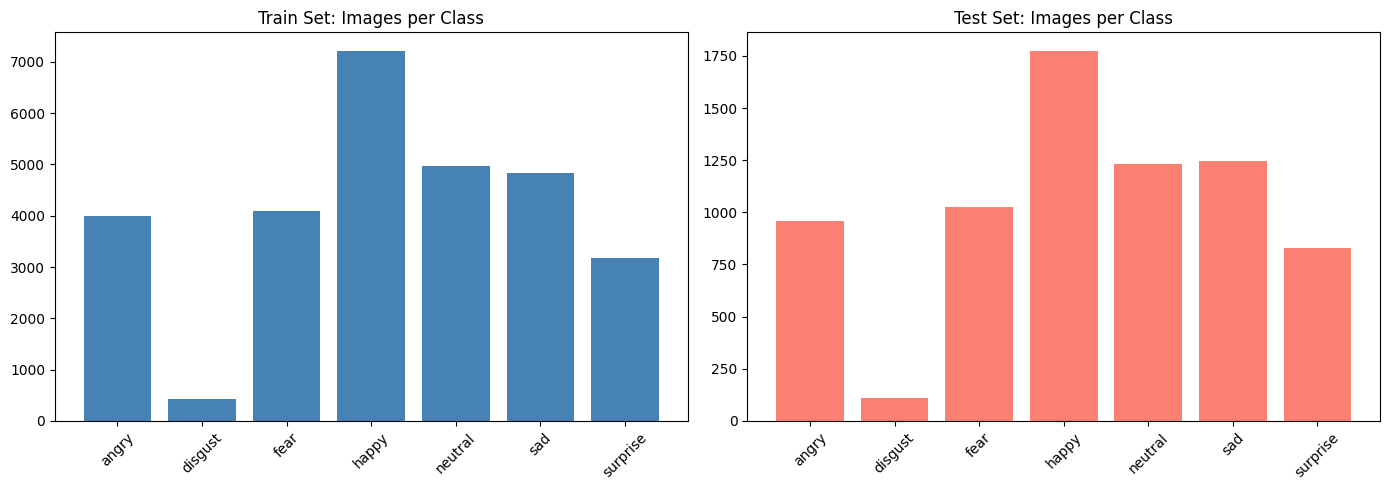


Total train images: 28709
Total test images:  7178


In [3]:
# SECTION 3: DATA LOADING & EXPLORATION

def count_images_per_class(root_dir, class_names):
    counts = {}
    for cls in class_names:
        cls_path = os.path.join(root_dir, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
        else:
            counts[cls] = 0
    return counts

train_counts = count_images_per_class(cfg.TRAIN_DIR, cfg.CLASS_NAMES)
test_counts  = count_images_per_class(cfg.TEST_DIR, cfg.CLASS_NAMES)

print("Train class distribution:", train_counts)
print("Test class distribution:", test_counts)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(train_counts.keys(), train_counts.values(), color="steelblue")
ax[0].set_title("Train Set: Images per Class")
ax[0].tick_params(axis='x', rotation=45)
ax[1].bar(test_counts.keys(), test_counts.values(), color="salmon")
ax[1].set_title("Test Set: Images per Class")
ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig("/kaggle/working/class_distribution.png", dpi=150)
plt.show()

total_train = sum(train_counts.values())
total_test  = sum(test_counts.values())
print(f"\nTotal train images: {total_train}")
print(f"Total test images:  {total_test}")

for cls, cnt in train_counts.items():
    if cnt == 0:
        print(f"⚠️  WARNING: No images found for class '{cls}'. Check cfg.TRAIN_DIR path.")

In [4]:
# SECTION 4: PREPROCESSING & AUGMENTATION

# ACCURACY NOTE: Added ColorJitter (brightness/contrast) since
# FER2013 has significant lighting variance across images —
# this is one of the more impactful augmentations for this
# specific dataset per published FER2013 ablation studies.

train_transform_cnn = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((cfg.IMG_SIZE_CNN, cfg.IMG_SIZE_CNN)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1))  # simulates occlusion, improves robustness
])

eval_transform_cnn = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((cfg.IMG_SIZE_CNN, cfg.IMG_SIZE_CNN)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Lighter augmentation for TTA (we don't want to distort too much, just add variety)
tta_transform_cnn = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.Resize((cfg.IMG_SIZE_CNN, cfg.IMG_SIZE_CNN)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

train_transform_resnet = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((cfg.IMG_SIZE_RESNET, cfg.IMG_SIZE_RESNET)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1))
])

eval_transform_resnet = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((cfg.IMG_SIZE_RESNET, cfg.IMG_SIZE_RESNET)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

tta_transform_resnet = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.Resize((cfg.IMG_SIZE_RESNET, cfg.IMG_SIZE_RESNET)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


def make_datasets(transform_train, transform_eval):
    full_train = datasets.ImageFolder(cfg.TRAIN_DIR)
    n_total = len(full_train)
    n_val = int(n_total * cfg.VAL_SPLIT)
    n_train = n_total - n_val

    generator = torch.Generator().manual_seed(SEED)
    train_subset, val_subset = torch.utils.data.random_split(
        full_train, [n_train, n_val], generator=generator
    )

    class TransformedSubset(torch.utils.data.Dataset):
        def __init__(self, subset, transform):
            self.subset = subset
            self.transform = transform
        def __len__(self):
            return len(self.subset)
        def __getitem__(self, idx):
            img, label = self.subset[idx]
            img = self.transform(img)
            return img, label

    train_ds = TransformedSubset(train_subset, transform_train)
    val_ds   = TransformedSubset(val_subset, transform_eval)
    test_ds  = datasets.ImageFolder(cfg.TEST_DIR, transform=transform_eval)

    return train_ds, val_ds, test_ds


train_ds_cnn, val_ds_cnn, test_ds_cnn = make_datasets(train_transform_cnn, eval_transform_cnn)
train_ds_resnet, val_ds_resnet, test_ds_resnet = make_datasets(train_transform_resnet, eval_transform_resnet)

print(f"CNN    -> train: {len(train_ds_cnn)}, val: {len(val_ds_cnn)}, test: {len(test_ds_cnn)}")
print(f"ResNet -> train: {len(train_ds_resnet)}, val: {len(val_ds_resnet)}, test: {len(test_ds_resnet)}")

train_loader_cnn = DataLoader(train_ds_cnn, batch_size=cfg.BATCH_SIZE, shuffle=True, num_workers=cfg.NUM_WORKERS)
val_loader_cnn   = DataLoader(val_ds_cnn, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)
test_loader_cnn  = DataLoader(test_ds_cnn, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)

train_loader_resnet = DataLoader(train_ds_resnet, batch_size=cfg.BATCH_SIZE, shuffle=True, num_workers=cfg.NUM_WORKERS)
val_loader_resnet   = DataLoader(val_ds_resnet, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)
test_loader_resnet  = DataLoader(test_ds_resnet, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)

sample_imgs_cnn, sample_labels_cnn = next(iter(train_loader_cnn))
print(f"CNN batch shape: {sample_imgs_cnn.shape}")
sample_imgs_resnet, sample_labels_resnet = next(iter(train_loader_resnet))
print(f"ResNet batch shape: {sample_imgs_resnet.shape}")

CNN    -> train: 25839, val: 2870, test: 7178
ResNet -> train: 25839, val: 2870, test: 7178
CNN batch shape: torch.Size([64, 1, 48, 48])
ResNet batch shape: torch.Size([64, 3, 224, 224])


In [5]:
# SECTION 5: CLASS WEIGHTS

full_train_targets = np.array(train_ds_cnn.subset.dataset.targets)
train_indices = train_ds_cnn.subset.indices
train_labels_only = full_train_targets[train_indices]

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(cfg.NUM_CLASSES),
    y=train_labels_only
)
class_weights = torch.tensor(class_weights_array, dtype=torch.float32).to(device)

print("Class weights (order = CLASS_NAMES):")
for name, w in zip(cfg.CLASS_NAMES, class_weights_array):
    print(f"  {name:10s}: {w:.3f}")

Class weights (order = CLASS_NAMES):
  angry     : 1.020
  disgust   : 9.417
  fear      : 1.005
  happy     : 0.569
  neutral   : 0.829
  sad       : 0.847
  surprise  : 1.291


In [6]:
# SECTION 6: MODEL A — CUSTOM CNN (with Global Average Pooling)
# ACCURACY NOTE: Replaced the large Flatten+FC(2304->256) head
# with Global Average Pooling (GAP) before the final FC layer.
# GAP has far fewer parameters than a big flatten+FC, which
# reduces overfitting on FER2013's relatively small training
# set — a well-documented trick (used in ResNet, etc.) for
# improving generalization on small image classifiers.

class DeepFER_CNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )  # -> 32 x 24 x 24

        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )  # -> 64 x 12 x 12

        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.3)
        )  # -> 128 x 6 x 6

        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),   # added extra conv for more capacity
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3)
        )  # -> 256 x 6 x 6 (no pooling here, GAP handles it below)

        self.gap = nn.AdaptiveAvgPool2d(1)   # -> 256 x 1 x 1
        self.flatten = nn.Flatten()

        self.head = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.gap(x)
        x = self.flatten(x)
        x = self.head(x)
        return x


model_cnn = DeepFER_CNN(num_classes=cfg.NUM_CLASSES).to(device)

total_params = sum(p.numel() for p in model_cnn.parameters())
trainable_params = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)
print(f"DeepFER_CNN — total params: {total_params:,}, trainable: {trainable_params:,}")

with torch.no_grad():
    dummy = torch.randn(2, 1, cfg.IMG_SIZE_CNN, cfg.IMG_SIZE_CNN).to(device)
    out = model_cnn(dummy)
    print(f"Sanity check output shape: {out.shape}")

DeepFER_CNN — total params: 1,207,399, trainable: 1,207,399
Sanity check output shape: torch.Size([2, 7])


In [7]:
# SECTION 7: MODEL B — TRANSFER LEARNING (ResNet34)
# ACCURACY NOTE: Switched ResNet18 -> ResNet34. Deeper backbone
# with a higher accuracy ceiling on ImageNet, still fast enough
# on a T4 GPU. Also unfreezing layer3+layer4 (not just layer4)
# in Phase 2 gives the model more capacity to re-adapt
# mid-to-high level features from "generic objects" (ImageNet)
# toward "facial expression" features.

def build_resnet_model(num_classes=7):
    backbone = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)

    for param in backbone.parameters():
        param.requires_grad = False

    in_features = backbone.fc.in_features  # 512 for ResNet34
    backbone.fc = nn.Sequential(
        nn.Linear(in_features, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.4),
        nn.Linear(256, num_classes)
    )

    return backbone

model_resnet = build_resnet_model(num_classes=cfg.NUM_CLASSES).to(device)

total_params_r = sum(p.numel() for p in model_resnet.parameters())
trainable_params_r = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
print(f"DeepFER_ResNet — total params: {total_params_r:,}, trainable (Phase 1): {trainable_params_r:,}")

with torch.no_grad():
    dummy_r = torch.randn(2, 3, cfg.IMG_SIZE_RESNET, cfg.IMG_SIZE_RESNET).to(device)
    out_r = model_resnet(dummy_r)
    print(f"Sanity check output shape: {out_r.shape}")


def unfreeze_layers(model, layer_names=("layer3", "layer4")):
    """Unfreezes the specified layer blocks for Phase 2 fine-tuning."""
    for name in layer_names:
        layer = getattr(model, name)
        for param in layer.parameters():
            param.requires_grad = True
    return model

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 178MB/s] 


DeepFER_ResNet — total params: 21,417,799, trainable (Phase 1): 133,127
Sanity check output shape: torch.Size([2, 7])


In [8]:
# SECTION 8: TRAINING UTILITIES

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        # Gradient clipping — helps stabilize training, especially
        # useful with the deeper ResNet34 during fine-tuning
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


def validate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    macro_f1 = f1_score(all_labels, all_preds, average="macro")
    return epoch_loss, epoch_acc, macro_f1, all_preds, all_labels


def run_training(model, train_loader, val_loader, criterion, optimizer,
                  scheduler, num_epochs, checkpoint_name, patience=10):
    """
    FIX APPLIED: always saves a checkpoint on epoch 1, so a
    checkpoint file is guaranteed to exist even if val_f1
    happens to be 0.0 early on (this was a real bug in the
    previous version that could crash the reload step).

    ACCURACY NOTE: added early stopping (patience) — stops
    training if val_f1 hasn't improved in `patience` epochs,
    preventing wasted epochs / overfitting on plateaued runs.
    """
    best_f1 = 0.0
    epochs_without_improvement = 0
    history = {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": [], "val_f1": []
    }

    checkpoint_path = os.path.join(cfg.CHECKPOINT_DIR, checkpoint_name)

    for epoch in range(1, num_epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, val_f1, _, _ = validate(model, val_loader, criterion)

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)

        current_lr = optimizer.param_groups[0]["lr"]
        print(f"Epoch {epoch:02d}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f} | "
              f"LR: {current_lr:.2e}")

        # Always save on epoch 1 (guarantees checkpoint exists),
        # otherwise only save on improvement.
        if val_f1 > best_f1 or epoch == 1:
            best_f1 = val_f1
            epochs_without_improvement = 0
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  -> New best model saved (macro-F1: {best_f1:.4f})")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"  Early stopping triggered (no improvement for {patience} epochs).")
            break

    return history


In [9]:
# SECTION 9: TRAIN MODEL A (Custom CNN)
criterion_cnn = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=cfg.LABEL_SMOOTHING)
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=cfg.CNN_LR, weight_decay=1e-4)
scheduler_cnn = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_cnn, mode="min", factor=0.5, patience=4
)

print("\n" + "=" * 60)
print("TRAINING MODEL A: Custom CNN")
print("=" * 60)

history_cnn = run_training(
    model=model_cnn,
    train_loader=train_loader_cnn,
    val_loader=val_loader_cnn,
    criterion=criterion_cnn,
    optimizer=optimizer_cnn,
    scheduler=scheduler_cnn,
    num_epochs=cfg.CNN_EPOCHS,
    checkpoint_name="best_cnn.pth",
    patience=12
)

model_cnn.load_state_dict(torch.load(os.path.join(cfg.CHECKPOINT_DIR, "best_cnn.pth")))


TRAINING MODEL A: Custom CNN
Epoch 01/60 | Train Loss: 2.1260 Acc: 0.0604 | Val Loss: 2.0992 Acc: 0.1125 F1: 0.0608 | LR: 1.00e-03
  -> New best model saved (macro-F1: 0.0608)
Epoch 02/60 | Train Loss: 2.0477 Acc: 0.1022 | Val Loss: 1.9702 Acc: 0.1146 F1: 0.1113 | LR: 1.00e-03
  -> New best model saved (macro-F1: 0.1113)
Epoch 03/60 | Train Loss: 1.9748 Acc: 0.1966 | Val Loss: 1.8759 Acc: 0.2826 F1: 0.2461 | LR: 1.00e-03
  -> New best model saved (macro-F1: 0.2461)
Epoch 04/60 | Train Loss: 1.9225 Acc: 0.2708 | Val Loss: 1.8440 Acc: 0.3254 F1: 0.2436 | LR: 1.00e-03
Epoch 05/60 | Train Loss: 1.8714 Acc: 0.3384 | Val Loss: 1.8022 Acc: 0.3460 F1: 0.2957 | LR: 1.00e-03
  -> New best model saved (macro-F1: 0.2957)
Epoch 06/60 | Train Loss: 1.8440 Acc: 0.3727 | Val Loss: 1.8112 Acc: 0.2937 F1: 0.2502 | LR: 1.00e-03
Epoch 07/60 | Train Loss: 1.8132 Acc: 0.3963 | Val Loss: 1.6893 Acc: 0.4509 F1: 0.3307 | LR: 1.00e-03
  -> New best model saved (macro-F1: 0.3307)
Epoch 08/60 | Train Loss: 1.800

<All keys matched successfully>

In [10]:
# SECTION 10: TRAIN MODEL B (ResNet34 Transfer Learning)

criterion_resnet = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=cfg.LABEL_SMOOTHING)

# ---- Phase 1: train head only (backbone frozen) ----
optimizer_resnet_p1 = optim.Adam(
    filter(lambda p: p.requires_grad, model_resnet.parameters()),
    lr=cfg.RESNET_HEAD_LR, weight_decay=1e-4
)
scheduler_resnet_p1 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_resnet_p1, mode="min", factor=0.5, patience=3
)

print("\n" + "=" * 60)
print("TRAINING MODEL B: ResNet34 — Phase 1 (frozen backbone)")
print("=" * 60)

history_resnet_p1 = run_training(
    model=model_resnet,
    train_loader=train_loader_resnet,
    val_loader=val_loader_resnet,
    criterion=criterion_resnet,
    optimizer=optimizer_resnet_p1,
    scheduler=scheduler_resnet_p1,
    num_epochs=cfg.RESNET_FROZEN_EPOCHS,
    checkpoint_name="best_resnet_phase1.pth",
    patience=8
)

# ---- Phase 2: unfreeze layer3+layer4, fine-tune with lower LR ----
model_resnet = unfreeze_layers(model_resnet, ("layer3", "layer4"))

optimizer_resnet_p2 = optim.Adam(
    filter(lambda p: p.requires_grad, model_resnet.parameters()),
    lr=cfg.RESNET_FINETUNE_LR, weight_decay=1e-4
)
scheduler_resnet_p2 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_resnet_p2, mode="min", factor=0.5, patience=4
)

trainable_now = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)
print(f"\nTrainable params after unfreezing layer3+layer4: {trainable_now:,}")

print("\n" + "=" * 60)
print("TRAINING MODEL B: ResNet34 — Phase 2 (fine-tuning layer3+layer4 + head)")
print("=" * 60)

history_resnet_p2 = run_training(
    model=model_resnet,
    train_loader=train_loader_resnet,
    val_loader=val_loader_resnet,
    criterion=criterion_resnet,
    optimizer=optimizer_resnet_p2,
    scheduler=scheduler_resnet_p2,
    num_epochs=cfg.RESNET_FINETUNE_EPOCHS,
    checkpoint_name="best_resnet_phase2.pth",
    patience=12
)

model_resnet.load_state_dict(torch.load(os.path.join(cfg.CHECKPOINT_DIR, "best_resnet_phase2.pth")))

history_resnet = {
    key: history_resnet_p1[key] + history_resnet_p2[key]
    for key in history_resnet_p1
}


TRAINING MODEL B: ResNet34 — Phase 1 (frozen backbone)
Epoch 01/8 | Train Loss: 2.1173 Acc: 0.0802 | Val Loss: 2.0455 Acc: 0.0557 F1: 0.0709 | LR: 1.00e-04
  -> New best model saved (macro-F1: 0.0709)
Epoch 02/8 | Train Loss: 2.0703 Acc: 0.1381 | Val Loss: 2.0046 Acc: 0.1690 F1: 0.1760 | LR: 1.00e-04
  -> New best model saved (macro-F1: 0.1760)
Epoch 03/8 | Train Loss: 2.0419 Acc: 0.1611 | Val Loss: 1.9806 Acc: 0.1380 F1: 0.1538 | LR: 1.00e-04
Epoch 04/8 | Train Loss: 2.0243 Acc: 0.1746 | Val Loss: 1.9716 Acc: 0.2690 F1: 0.2423 | LR: 1.00e-04
  -> New best model saved (macro-F1: 0.2423)
Epoch 05/8 | Train Loss: 2.0211 Acc: 0.1897 | Val Loss: 1.9683 Acc: 0.3293 F1: 0.2805 | LR: 1.00e-04
  -> New best model saved (macro-F1: 0.2805)
Epoch 06/8 | Train Loss: 2.0126 Acc: 0.1982 | Val Loss: 1.9514 Acc: 0.2990 F1: 0.2598 | LR: 1.00e-04
Epoch 07/8 | Train Loss: 2.0063 Acc: 0.2062 | Val Loss: 1.9439 Acc: 0.2889 F1: 0.2597 | LR: 1.00e-04
Epoch 08/8 | Train Loss: 1.9968 Acc: 0.2217 | Val Loss: 1

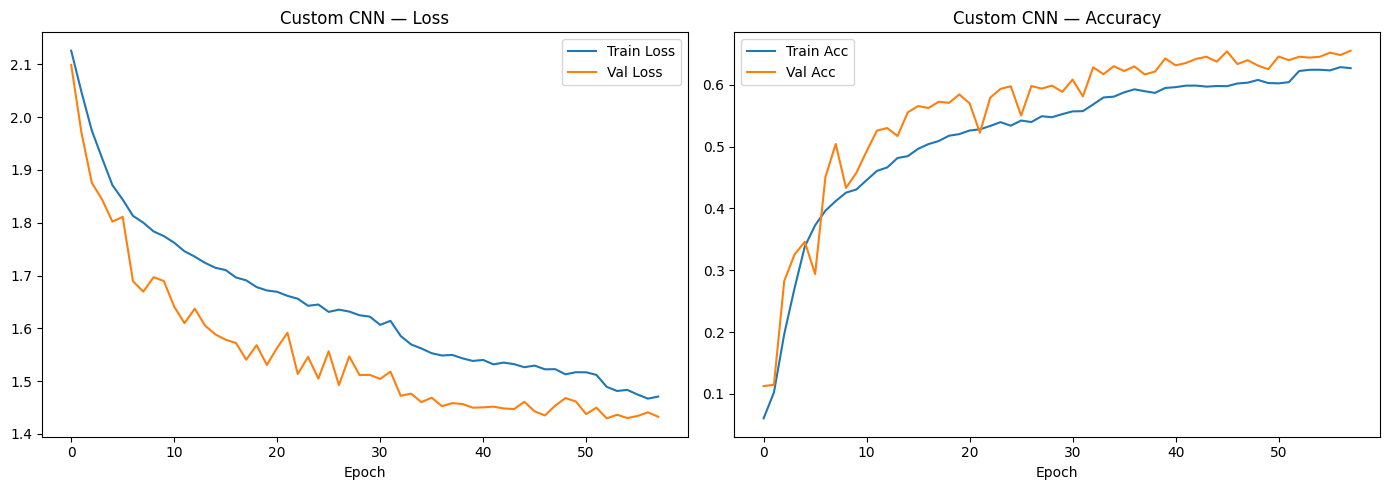

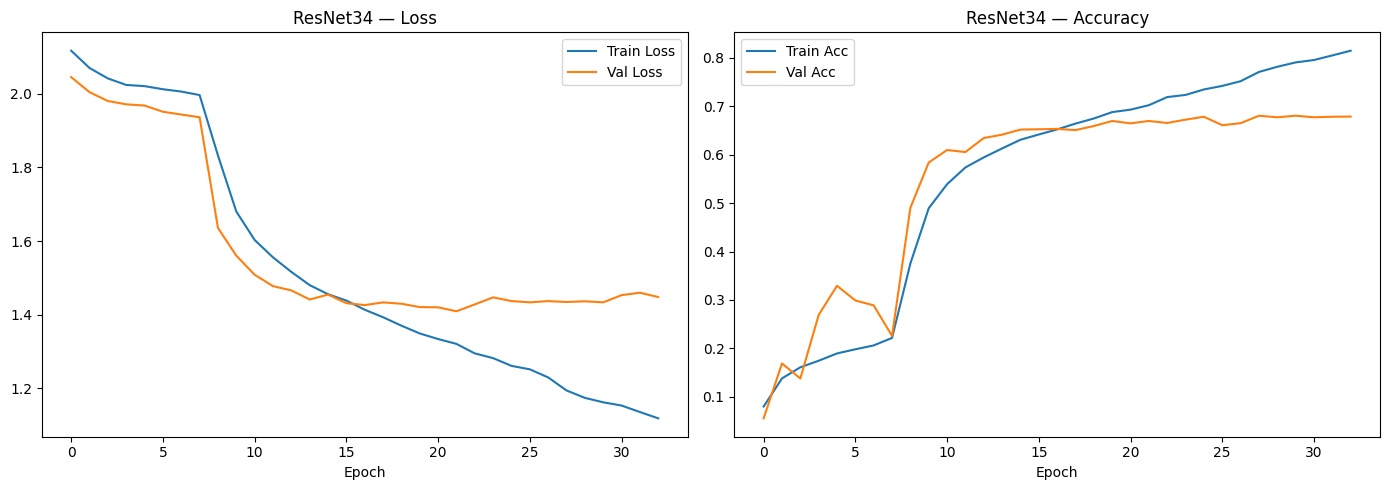


FINAL TEST SET EVALUATION (with Test-Time Augmentation)

Custom CNN (TTA) — Test Acc: 0.6478 | Test Macro-F1: 0.6034
              precision    recall  f1-score   support

       angry       0.56      0.62      0.59       958
     disgust       0.33      0.70      0.45       111
        fear       0.52      0.32      0.39      1024
       happy       0.91      0.82      0.86      1774
     neutral       0.59      0.67      0.62      1233
         sad       0.53      0.54      0.54      1247
    surprise       0.71      0.84      0.77       831

    accuracy                           0.65      7178
   macro avg       0.59      0.64      0.60      7178
weighted avg       0.65      0.65      0.64      7178



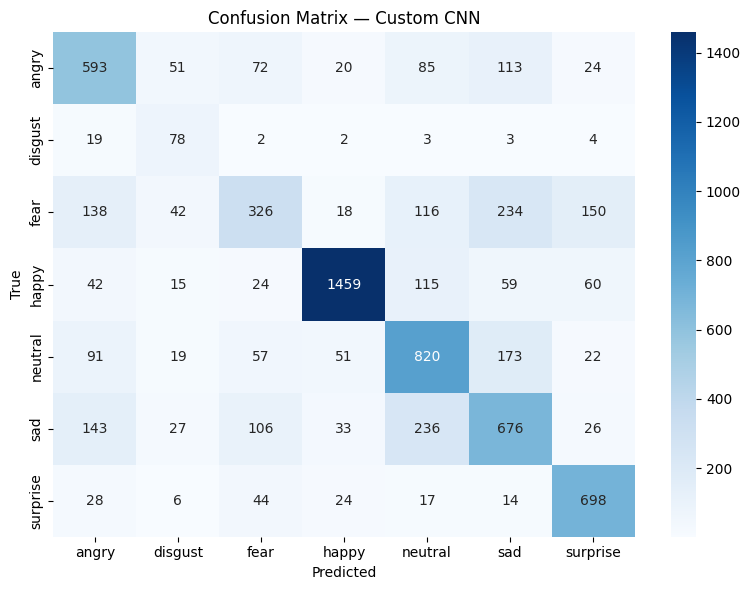


ResNet34 (TTA) — Test Acc: 0.6878 | Test Macro-F1: 0.6682
              precision    recall  f1-score   support

       angry       0.56      0.69      0.61       958
     disgust       0.64      0.68      0.66       111
        fear       0.60      0.43      0.50      1024
       happy       0.90      0.87      0.88      1774
     neutral       0.62      0.70      0.66      1233
         sad       0.58      0.53      0.56      1247
    surprise       0.77      0.84      0.80       831

    accuracy                           0.69      7178
   macro avg       0.67      0.68      0.67      7178
weighted avg       0.69      0.69      0.68      7178



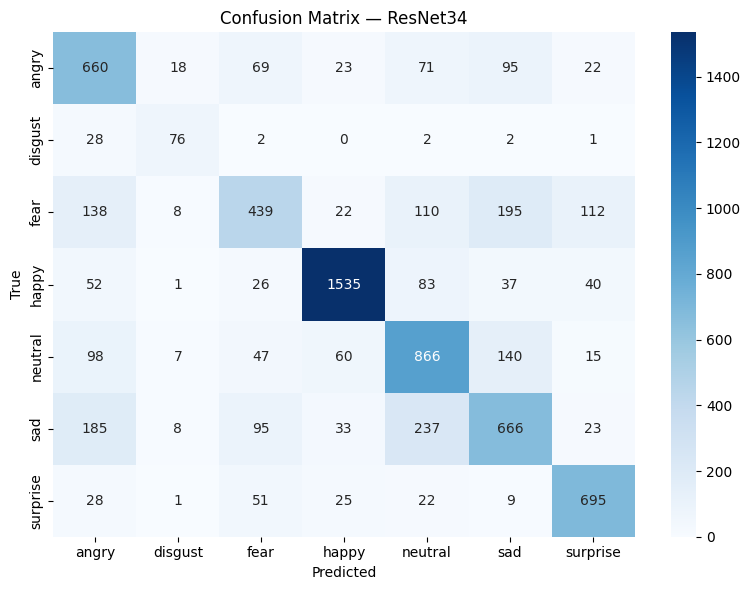


Model Comparison:
                       Model  Test Accuracy (TTA)  Test Macro-F1 (TTA)  Total Params
                  Custom CNN             0.647813             0.603443       1207399
ResNet34 (Transfer Learning)             0.687796             0.668173      21417799


In [11]:
# SECTION 11: EVALUATION & COMPARISON (with TTA)
# ACCURACY NOTE: Test-Time Augmentation (TTA) — instead of
# evaluating each test image once, we evaluate it several times
# with light random augmentation and average the softmax
# probabilities. This is a well-known technique that typically
# adds +1-3% accuracy "for free" (no retraining needed).

def evaluate_with_tta(model, test_dir, tta_transform, eval_transform,
                       class_names, num_rounds=5):
    """
    Runs TTA evaluation: averages softmax probabilities across
    `num_rounds` differently-augmented passes over the test set,
    plus one pass with the plain (non-augmented) eval transform.
    """
    model.eval()

    # Build one dataset per round (each with its own random augmentation draw)
    tta_datasets = [
        datasets.ImageFolder(test_dir, transform=tta_transform)
        for _ in range(num_rounds)
    ]
    plain_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)

    tta_loaders = [
        DataLoader(ds, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)
        for ds in tta_datasets
    ]
    plain_loader = DataLoader(plain_dataset, batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=cfg.NUM_WORKERS)

    all_probs = None
    true_labels = None

    all_loaders = [plain_loader] + tta_loaders

    for loader in all_loaders:
        round_probs = []
        round_labels = []
        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                outputs = model(images)
                probs = F.softmax(outputs, dim=1).cpu().numpy()
                round_probs.append(probs)
                round_labels.append(labels.numpy())
        round_probs = np.concatenate(round_probs, axis=0)
        round_labels = np.concatenate(round_labels, axis=0)

        if all_probs is None:
            all_probs = round_probs
            true_labels = round_labels
        else:
            all_probs += round_probs

    avg_probs = all_probs / len(all_loaders)
    final_preds = avg_probs.argmax(axis=1)

    acc = (final_preds == true_labels).mean()
    macro_f1 = f1_score(true_labels, final_preds, average="macro")

    return acc, macro_f1, final_preds, true_labels


def plot_training_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["val_loss"], label="Val Loss")
    axes[0].set_title(f"{title} — Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="Train Acc")
    axes[1].plot(history["val_acc"], label="Val Acc")
    axes[1].set_title(f"{title} — Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    safe_title = title.lower().replace(" ", "_")
    plt.savefig(f"/kaggle/working/{safe_title}_curves.png", dpi=150)
    plt.show()


def plot_confusion_matrix(labels, preds, class_names, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix — {title}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    safe_title = title.lower().replace(" ", "_")
    plt.savefig(f"/kaggle/working/{safe_title}_confusion_matrix.png", dpi=150)
    plt.show()


plot_training_curves(history_cnn, "Custom CNN")
plot_training_curves(history_resnet, "ResNet34")

print("\n" + "=" * 60)
print("FINAL TEST SET EVALUATION (with Test-Time Augmentation)")
print("=" * 60)

test_acc_cnn, test_f1_cnn, preds_cnn, labels_cnn = evaluate_with_tta(
    model_cnn, cfg.TEST_DIR, tta_transform_cnn, eval_transform_cnn,
    cfg.CLASS_NAMES, num_rounds=cfg.TTA_ROUNDS
)
print(f"\nCustom CNN (TTA) — Test Acc: {test_acc_cnn:.4f} | Test Macro-F1: {test_f1_cnn:.4f}")
print(classification_report(labels_cnn, preds_cnn, target_names=cfg.CLASS_NAMES))
plot_confusion_matrix(labels_cnn, preds_cnn, cfg.CLASS_NAMES, "Custom CNN")

test_acc_resnet, test_f1_resnet, preds_resnet, labels_resnet = evaluate_with_tta(
    model_resnet, cfg.TEST_DIR, tta_transform_resnet, eval_transform_resnet,
    cfg.CLASS_NAMES, num_rounds=cfg.TTA_ROUNDS
)
print(f"\nResNet34 (TTA) — Test Acc: {test_acc_resnet:.4f} | Test Macro-F1: {test_f1_resnet:.4f}")
print(classification_report(labels_resnet, preds_resnet, target_names=cfg.CLASS_NAMES))
plot_confusion_matrix(labels_resnet, preds_resnet, cfg.CLASS_NAMES, "ResNet34")

comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "ResNet34 (Transfer Learning)"],
    "Test Accuracy (TTA)": [test_acc_cnn, test_acc_resnet],
    "Test Macro-F1 (TTA)": [test_f1_cnn, test_f1_resnet],
    "Total Params": [total_params, total_params_r]
})
print("\nModel Comparison:")
print(comparison_df.to_string(index=False))
comparison_df.to_csv("/kaggle/working/model_comparison.csv", index=False)

In [12]:
# SECTION 12: SAVE ARTIFACTS

import json

summary = {
    "class_names": cfg.CLASS_NAMES,
    "cnn_test_accuracy_tta": float(test_acc_cnn),
    "cnn_test_macro_f1_tta": float(test_f1_cnn),
    "resnet_test_accuracy_tta": float(test_acc_resnet),
    "resnet_test_macro_f1_tta": float(test_f1_resnet),
    "cnn_checkpoint": "checkpoints/best_cnn.pth",
    "resnet_checkpoint": "checkpoints/best_resnet_phase2.pth"
}

with open("/kaggle/working/summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nAll artifacts saved to /kaggle/working/.")
print("Done!")


All artifacts saved to /kaggle/working/.
Done!
